# TA-02 — Pembangkitan Bilangan Acak (RNG) & Random Variate
**Mata Praktikum:** Pemodelan dan Simulasi  
**Dosen Pengampu:** Mohammad Bayu Anggara, S.Kom., M.Kom.  
**Nama:** Dede Jamaludin  
**NIM:** 301240007  

Notebook ini membangun *Linear Congruential Generator* (LCG) secara manual (tanpa `np.random`/`random`), lalu memakainya untuk membangkitkan data berdistribusi Eksponensial dengan metode *Inverse Transform*.

## Import Library
Hanya `numpy` (untuk `np.log`, `np.mean`, dll.) dan `matplotlib` (visualisasi). **Tidak ada** fungsi acak bawaan library yang dipakai.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

NIM  = 301240007
NAMA = "Dede Jamaludin"
print(f"NIM  : {NIM}")
print(f"Nama : {NAMA}")

NIM  : 301240007
Nama : Dede Jamaludin


## Bagian 1 — Membangun Linear Congruential Generator (LCG)

Rumus rekursif:

$$X_{i+1} = (a \cdot X_i + c) \bmod m$$

dengan $a=1664525$, $c=1013904223$, $m=2^{32}=4294967296$, dan seed $X_0$ = NIM. Hasil dinormalisasi: $U_i = X_i / m$.

In [2]:
def my_lcg(n, seed, a, c, m):
    """Membangkitkan n bilangan acak (integer) dengan LCG.
    X_{i+1} = (a * X_i + c) mod m
    Mengembalikan list X_1 ... X_n (seed X_0 tidak ikut dikembalikan)."""
    hasil = []
    x = seed
    for _ in range(n):
        x = (a * x + c) % m
        hasil.append(x)
    return hasil

In [3]:
# Parameter LCG
a = 1664525
c = 1013904223
m = 2**32          # 4294967296
seed = NIM         # X0 = NIM
n = 1000

X = my_lcg(n, seed, a, c, m)
U = np.array(X) / m          # normalisasi ke (0, 1)

print("10 nilai X_i pertama :", X[:10])
print("10 nilai U_i pertama :", np.round(U[:10], 6))
print(f"Jumlah data          : {len(U)}")
print(f"Min U = {U.min():.6f} | Max U = {U.max():.6f}")

10 nilai X_i pertama : [2284617082, 563736209, 2457261756, 4267885291, 2316270414, 1962363477, 4142438320, 1121896271, 3688860770, 776609881]
10 nilai U_i pertama : [0.531929 0.131255 0.572126 0.993694 0.539299 0.456898 0.964487 0.261212
 0.85888  0.180819]
Jumlah data          : 1000
Min U = 0.002874 | Max U = 0.998762


In [4]:
# Uji reproducibility: seed sama -> deret sama
assert my_lcg(10, seed, a, c, m) == my_lcg(10, seed, a, c, m)
print("Seed yang sama menghasilkan deret yang identik -> reproducible")

Seed yang sama menghasilkan deret yang identik -> reproducible


### Histogram Data $U_i$ (Uniform)

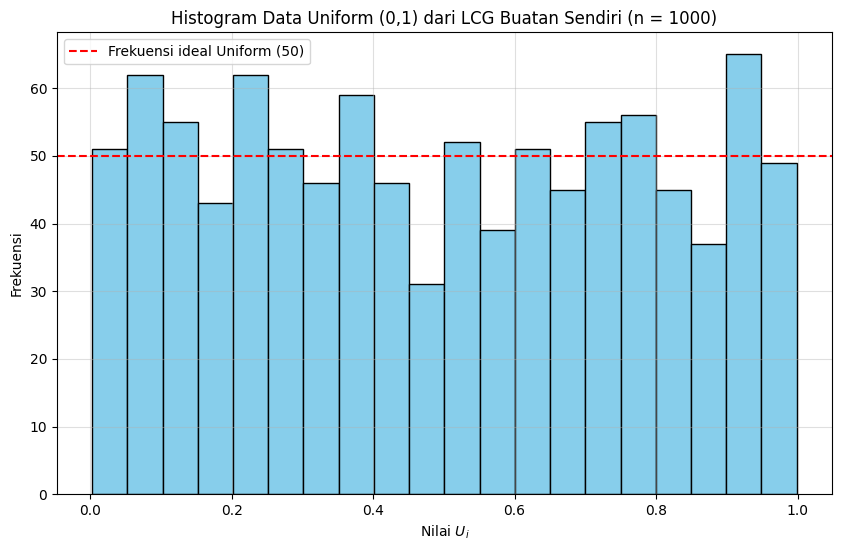

In [5]:
plt.figure(figsize=(10, 6))
plt.hist(U, bins=20, color='skyblue', edgecolor='black')
plt.axhline(n / 20, color='red', linestyle='--', label=f'Frekuensi ideal Uniform ({n//20})')
plt.title('Histogram Data Uniform (0,1) dari LCG Buatan Sendiri (n = 1000)')
plt.xlabel('Nilai $U_i$')
plt.ylabel('Frekuensi')
plt.legend()
plt.grid(True, alpha=0.4)
plt.savefig('histogram_uniform_lcg.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# Statistik pendukung & uji kerataan (chi-square manual)
frek, _ = np.histogram(U, bins=20, range=(0, 1))
ekspektasi = n / 20
chi2 = np.sum((frek - ekspektasi) ** 2 / ekspektasi)

print(f"Mean U   = {U.mean():.4f}   (teoritis 0.5000)")
print(f"Var  U   = {U.var():.4f}   (teoritis 1/12 = {1/12:.4f})")
print(f"Chi-square (20 bin, db=19) = {chi2:.3f}   (nilai kritis alpha=0.05 : 30.144)")
print("Kesimpulan uji:", "tidak ada bukti menolak Uniform" if chi2 < 30.144 else "sebaran menyimpang dari Uniform")

Mean U   = 0.4941   (teoritis 0.5000)
Var  U   = 0.0865   (teoritis 1/12 = 0.0833)
Chi-square (20 bin, db=19) = 24.160   (nilai kritis alpha=0.05 : 30.144)
Kesimpulan uji: tidak ada bukti menolak Uniform


## Bagian 2 — Inverse Transform Method

Untuk distribusi Eksponensial dengan laju $\lambda$, CDF-nya $F(x)=1-e^{-\lambda x}$. Dengan membalik CDF:

$$X = -\frac{1}{\lambda}\ln(1-U)$$

Karena $U$ dan $1-U$ sama-sama Uniform(0,1), rumus ini sering ditulis $-\ln(U)/\lambda$. Di sini dipakai bentuk $\ln(1-U)$ yang aman karena $U\in[0,1)$ sehingga $1-U>0$.  
Nilai $\lambda = 2$ (rata-rata 2 pelanggan/menit), jadi rata-rata teoritis waktu antar-kedatangan $=1/\lambda=0{,}5$ menit.

In [7]:
lam = 2
Xexp = -np.log(1 - U) / lam      # inverse transform

print("10 waktu antar-kedatangan pertama (menit):", np.round(Xexp[:10], 4))
print(f"Min = {Xexp.min():.4f} | Max = {Xexp.max():.4f}")

10 waktu antar-kedatangan pertama (menit): [0.3796 0.0704 0.4245 2.5332 0.3875 0.3052 1.6689 0.1514 0.9791 0.0997]
Min = 0.0014 | Max = 3.3470


### Histogram Data Eksponensial

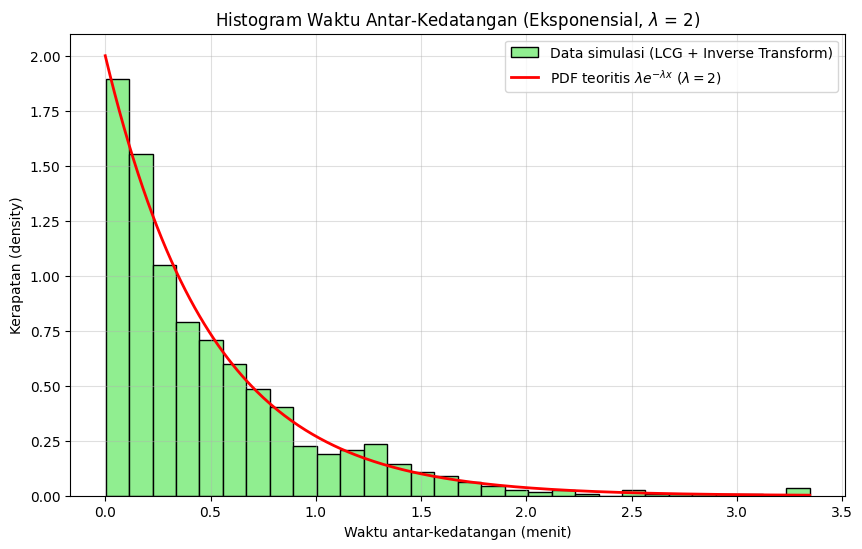

In [8]:
xs = np.linspace(0, Xexp.max(), 300)
pdf_teori = lam * np.exp(-lam * xs)      # f(x) = lambda * e^{-lambda x}

plt.figure(figsize=(10, 6))
plt.hist(Xexp, bins=30, density=True, color='lightgreen', edgecolor='black', label='Data simulasi (LCG + Inverse Transform)')
plt.plot(xs, pdf_teori, 'r-', linewidth=2, label=r'PDF teoritis $\lambda e^{-\lambda x}$ ($\lambda=2$)')
plt.title(r'Histogram Waktu Antar-Kedatangan (Eksponensial, $\lambda$ = 2)')
plt.xlabel('Waktu antar-kedatangan (menit)')
plt.ylabel('Kerapatan (density)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.savefig('histogram_eksponensial.png', dpi=150, bbox_inches='tight')
plt.show()

## Analisis: Rata-rata Simulasi vs Teoritis

In [9]:
rata_sim = Xexp.mean()
rata_teori = 1 / lam
selisih = abs(rata_sim - rata_teori)
galat_rel = selisih / rata_teori * 100
std_sim = Xexp.std()
se = std_sim / np.sqrt(n)      # standard error rata-rata

print(f"Rata-rata simulasi X_i : {rata_sim:.4f} menit")
print(f"Rata-rata teoritis 1/λ : {rata_teori:.4f} menit")
print(f"Selisih absolut        : {selisih:.4f}")
print(f"Galat relatif          : {galat_rel:.2f} %")
print(f"Std simulasi           : {std_sim:.4f}  (teoritis 1/λ = {rata_teori:.4f})")
print(f"Standard error mean    : {se:.4f}")
print(f"Selisih dalam satuan SE: {selisih/se:.2f}  (<2 berarti wajar secara statistik)")

Rata-rata simulasi X_i : 0.5007 menit
Rata-rata teoritis 1/λ : 0.5000 menit
Selisih absolut        : 0.0007
Galat relatif          : 0.14 %
Std simulasi           : 0.5159  (teoritis 1/λ = 0.5000)
Standard error mean    : 0.0163
Selisih dalam satuan SE: 0.04  (<2 berarti wajar secara statistik)


### Kesimpulan

1. **Uniform:** histogram $U_i$ relatif rata di seluruh interval (0,1); rata-rata mendekati 0,5, variansi mendekati 1/12, dan uji chi-square tidak menolak hipotesis Uniform.
2. **Eksponensial:** histogram $X_i$ menurun secara eksponensial (nilai kecil paling sering muncul) dan mengikuti kurva PDF teoritis $\lambda e^{-\lambda x}$.
3. **Rata-rata:** rata-rata simulasi $X_i$ mendekati nilai teoritis $1/\lambda = 0{,}5$ dengan selisih kecil (lihat sel di atas).
4. Dengan demikian, **generator LCG buatan sendiri cukup baik** untuk keperluan simulasi sederhana ini. Parameter $a, c, m$ yang dipakai (parameter klasik *Numerical Recipes*) memiliki periode penuh $2^{32}$, sehingga tidak berulang dalam 1.000 data. Catatan: LCG bukan generator berkualitas kriptografi dan korelasi antar-nilai berurutan tetap ada, sehingga untuk simulasi skala besar dipakai generator modern seperti PCG64 atau Mersenne Twister.